# Lab 2: Set cover with hill climbing
Generates the 100 set-cover instances S1...S100 and solves them with two hill-climbing variants: reject and penalty.


In [1]:
from random import random,sample,seed,Random,choice
from math import sqrt
from collections import namedtuple
from matplotlib import pyplot as plt

## Instance generation
Instance Sₙ has n objects and n sets; set fᵢ covers i+1 random objects and costs 10·U + √(i·U). Each instance has its own `Random(n)`, so it's reproducible.

In [2]:
Instance = namedtuple('Instance', ['objects', 'family', 'costs'])

In [3]:
def single_instance(n: int) -> Instance:
    rng = Random(n)
    family = tuple(frozenset(rng.sample(range(n), k=s+1)) for s in range(n))
    objects = frozenset(a for a in range(n))
    costs = tuple(10*rng.random()+ sqrt(s*rng.random()) for s in range(n))
   

    single = Instance(objects,family,costs)

    return single

In [4]:
single_instance(5)

Instance(objects=frozenset({0, 1, 2, 3, 4}), family=(frozenset({4}), frozenset({2, 4}), frozenset({0, 1, 4}), frozenset({0, 1, 2, 3}), frozenset({0, 1, 2, 3, 4})), costs=(5.739411879281008, 2.6959589224403464, 10.400971759674523, 3.142470581121698, 2.95923712636979))

In [5]:

def universe_generation(n: int) -> dict[int, Instance]:
    universe = {i: single_instance(i) for i in range(1,n+1)}
    return universe
    

In [6]:
universe_generation(3)

{1: Instance(objects=frozenset({0}), family=(frozenset({0}),), costs=(5.692038748222123,)),
 2: Instance(objects=frozenset({0, 1}), family=(frozenset({0}), frozenset({0, 1})), costs=(3.610574739836072, 9.013652039730971)),
 3: Instance(objects=frozenset({0, 1, 2}), family=(frozenset({0}), frozenset({0, 2}), frozenset({0, 1, 2})), costs=(6.055995301393269, 5.434472041728377, 3.11506204784191))}

## Evaluating a solution
A solution is a frozenset of chosen set indices. `evaluate` returns its total cost and the number of uncovered objects.

In [7]:
def evaluate(instance: Instance, solution: frozenset[int]) -> tuple[float,int]:
    total_cost = sum(instance.costs[i] for i in solution)
    covered = frozenset().union(*(instance.family[i] for i in solution))
    uncovered= len(instance.objects - covered)
    return total_cost, uncovered 

In [8]:
test = single_instance(5)
print(evaluate(test, frozenset({4})))
print(evaluate(test, frozenset()))
print(evaluate(test, frozenset(range(5))))

(2.95923712636979, 0)
(0, 5)
(24.938050268887366, 0)


## Tweak
Makes one random move (add, remove or swap a set), choosing only among moves that are possible.

In [9]:
def tweak(instance: Instance, solution: frozenset[int], rng: Random) -> frozenset[int]:
    
    all_indices = frozenset(range(len(instance.family)))
    inside = solution
    outside = all_indices - inside

    possible_moves = []
    if inside:
        possible_moves.append('remove')
    if outside:
        possible_moves.append('add')
    if inside and outside:
        possible_moves.append('swap')

    # rng instead of the shared choice(), so runs are reproducible
    move = rng.choice(possible_moves)
    # sorted() always has the same order, so a given seed
    # always picks the same index
    if move == 'remove':
        removed = rng.choice(sorted(inside))
        new_solution = inside - {removed}           
    elif move == 'add':
        added = rng.choice(sorted(outside))
        new_solution = inside | {added}
    else:  
        removed = rng.choice(sorted(inside))
        added = rng.choice(sorted(outside))
        new_solution = (inside - {removed}) | {added}
    return new_solution



## Scoring
Reject: invalid solutions score infinity. Penalty: cost + weight × uncovered objects. Lower is better.

In [10]:
def reject_scoring(evaluation: tuple[float,int]) -> float:
    cost, uncovered = evaluation
    if uncovered > 0:
        return float('inf')
    else:
        return cost
    

In [11]:
single = single_instance(5)
sol1= frozenset({4})
sol2= frozenset({1,4})
sol3= frozenset({1})
sol4= frozenset()
for sol in [sol1, sol2, sol3, sol4]:
    print(f"solution: {sol}, evaluation: {evaluate(single, sol)}, reject scoring: {reject_scoring(evaluate(single, sol))}")

solution: frozenset({4}), evaluation: (2.95923712636979, 0), reject scoring: 2.95923712636979
solution: frozenset({1, 4}), evaluation: (5.6551960488101365, 0), reject scoring: 5.6551960488101365
solution: frozenset({1}), evaluation: (2.6959589224403464, 3), reject scoring: inf
solution: frozenset(), evaluation: (0, 5), reject scoring: inf


In [12]:
def penalty_scoring(evaluation: tuple[float,int], weight: float) -> float:
    cost, uncovered = evaluation
    return cost + weight * uncovered
    

In [13]:
single = single_instance(5)
sol1= frozenset({4})
sol2= frozenset({1,4})
sol3= frozenset({1})
sol4= frozenset()
for sol in [sol1, sol2, sol3, sol4]:
    print(f"solution: {sol}, evaluation: {evaluate(single, sol)}, penalty scoring lambda1: {penalty_scoring(evaluate(single, sol), weight=1)}")
    print(f"solution: {sol}, evaluation: {evaluate(single, sol)}, penalty scoring lambda0.5: {penalty_scoring(evaluate(single, sol), weight=0.5)}")

solution: frozenset({4}), evaluation: (2.95923712636979, 0), penalty scoring lambda1: 2.95923712636979
solution: frozenset({4}), evaluation: (2.95923712636979, 0), penalty scoring lambda0.5: 2.95923712636979
solution: frozenset({1, 4}), evaluation: (5.6551960488101365, 0), penalty scoring lambda1: 5.6551960488101365
solution: frozenset({1, 4}), evaluation: (5.6551960488101365, 0), penalty scoring lambda0.5: 5.6551960488101365
solution: frozenset({1}), evaluation: (2.6959589224403464, 3), penalty scoring lambda1: 5.695958922440346
solution: frozenset({1}), evaluation: (2.6959589224403464, 3), penalty scoring lambda0.5: 4.195958922440346
solution: frozenset(), evaluation: (0, 5), penalty scoring lambda1: 5
solution: frozenset(), evaluation: (0, 5), penalty scoring lambda0.5: 2.5


## Hill climbing: reject
Starts from all sets and accepts equal or better tweaks. stops after 1000 tweaks in a row without improvement.

In [14]:
def hill_climb_reject(instance: Instance, rng: Random, patience: int = 1000, max_steps: int = 100_000) -> tuple[frozenset[int], float, list[float]]:
    current = frozenset(range(len(instance.family)))
    current_score = reject_scoring(evaluate(instance, current))
    history = [current_score]
    no_improvement_steps = 0
    for step in range(max_steps):
        candidate = tweak(instance, current, rng)
        candidate_score = reject_scoring(evaluate(instance, candidate))
        if candidate_score < current_score:
            current, current_score = candidate, candidate_score
            no_improvement_steps = 0
        elif candidate_score == current_score:
            current, current_score = candidate, candidate_score
            no_improvement_steps += 1
        else:
            no_improvement_steps += 1
        history.append(current_score)
        if no_improvement_steps >= patience:
            break
    return current, current_score, history

In [15]:
inst = single_instance(5)
best, best_score, hist = hill_climb_reject(inst, Random(0))
print(f"Best solution: {best}, Best score: {best_score}")


Best solution: frozenset({4}), Best score: 2.95923712636979


Instance: Instance(objects=frozenset({0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38}), family=(frozenset({13}), frozenset({16, 24}), frozenset({1, 12, 14}), frozenset({0, 25, 36, 16}), frozenset({1, 4, 11, 18, 22}), frozenset({0, 35, 6, 22, 23, 27}), frozenset({32, 4, 6, 17, 19, 25, 29}), frozenset({0, 2, 36, 12, 16, 20, 27, 30}), frozenset({2, 38, 8, 18, 20, 22, 24, 27, 30}), frozenset({1, 5, 6, 11, 13, 15, 18, 19, 25, 30}), frozenset({0, 1, 6, 7, 8, 14, 16, 20, 24, 26, 28}), frozenset({34, 5, 6, 8, 14, 15, 17, 21, 23, 27, 30, 31}), frozenset({32, 1, 3, 5, 6, 9, 10, 11, 12, 18, 20, 23, 31}), frozenset({32, 33, 3, 4, 35, 6, 7, 8, 38, 11, 14, 21, 26, 29}), frozenset({0, 33, 34, 35, 4, 5, 3, 6, 9, 11, 17, 18, 20, 25, 29}), frozenset({37, 6, 8, 9, 10, 11, 13, 14, 18, 21, 22, 24, 27, 28, 30, 31}), frozenset({0, 1, 34, 3, 4, 6, 8, 11, 15, 16, 21, 24, 25, 26, 27, 29, 30}), frozenset({1, 2, 3, 3

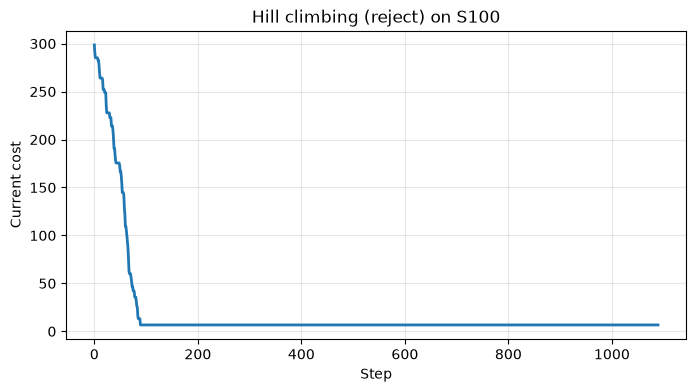

Best solution: frozenset({38}), Best score: 6.6824108323750355


In [16]:
inst = single_instance(39)
print(f"Instance: {inst}")
best, best_score, hist = hill_climb_reject(inst, Random(0))

plt.figure(figsize=(8, 4))                    # new, empty figure: 8 wide, 4 tall (in inches)
plt.plot(hist, linewidth=2)                   # draw the history as a line
plt.xlabel("Step")                            # label the x axis
plt.ylabel("Current cost")                    # label the y axis
plt.title("Hill climbing (reject) on S100")    # title above the plot
plt.grid(alpha=0.3)                           # faint grid lines (alpha = transparency)
plt.show()                                    # display it
print(f"Best solution: {best}, Best score: {best_score}")


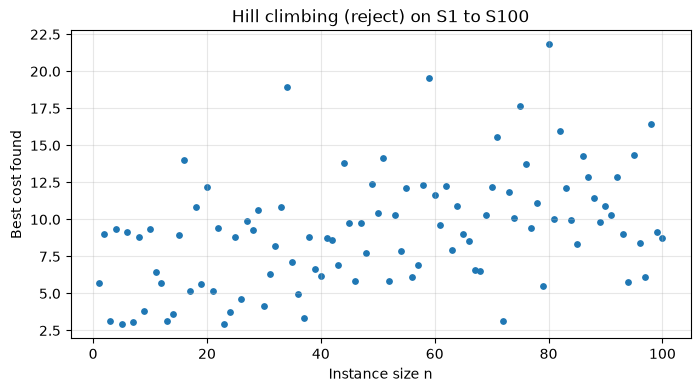

In [17]:
ns = []       # x values: instance size
costs = []    # y values: best cost found

for n in range(1, 101):
    _, score, _ = hill_climb_reject(single_instance(n), Random(0))
    ns.append(n)
    costs.append(score)

plt.figure(figsize=(8, 4))
plt.scatter(ns, costs, s=15)                  # one dot per instance (s = dot size)
plt.xlabel("Instance size n")
plt.ylabel("Best cost found")
plt.title("Hill climbing (reject) on S1 to S100")
plt.grid(alpha=0.3)
plt.show()


## Hill climbing: penalty
Same loop but with penalty scoring. Can pass through invalid solutions, so it returns the best valid solution seen.

In [ ]:
def hill_climb_penalty(instance: Instance, rng: Random, weight: float,
                       patience: int = 1000, max_steps: int = 100_000) -> tuple[frozenset[int], float, list[float]]:
    current = frozenset(range(len(instance.family)))
    current_eval = evaluate(instance, current)                 
    current_cost, current_uncovered = current_eval
    current_score = penalty_scoring(current_eval, weight)
    history = [current_score]
    no_improvement_steps = 0

    best_valid = current                                            
    best_valid_cost = current_cost                                     

    for step in range(max_steps):
        candidate = tweak(instance, current, rng)
        candidate_eval = evaluate(instance, candidate)          
        candidate_score = penalty_scoring(candidate_eval, weight)

        if candidate_score < current_score:
            current, current_score = candidate, candidate_score
            no_improvement_steps = 0
        elif candidate_score == current_score:
            current, current_score = candidate, candidate_score
            no_improvement_steps += 1
        else:
            no_improvement_steps += 1

        #  best valid solution
        cand_cost, cand_uncovered = candidate_eval
        if cand_uncovered == 0 and cand_cost<best_valid_cost:                                         # valid AND cheaper than best_valid_cost
            best_valid, best_valid_cost = candidate, cand_cost

        history.append(current_score)
        if no_improvement_steps >= patience:
            break

    return best_valid, best_valid_cost, history             


In [28]:
inst = single_instance(59)
for w in [1,5, 25]:
    sol, cost, hist = hill_climb_penalty(inst, Random(0), weight=w)
    print(f"weight={w}: best valid {sorted(sol)}, cost {cost:.2f}, steps {len(hist)}")


weight=1: best valid [58], cost 9.78, steps 2438
weight=5: best valid [58], cost 9.78, steps 1232
weight=25: best valid [29, 38, 42], cost 19.56, steps 1197


In [20]:
inst = single_instance(5)
for w in [25, 0.5]:
    sol, cost, hist = hill_climb_penalty(inst, Random(0), weight=w)
    print(f"weight={w}: best valid {sorted(sol)}, cost {cost:.2f}, steps {len(hist)}")


weight=25: best valid [4], cost 2.96, steps 1011
weight=0.5: best valid [4], cost 2.96, steps 1017


## Comparison on S1...S100
Runs reject and penalty (weights 1, 5, 25) on all instances, then summarises them against reject and plots them.

In [34]:
ns = list(range(1, 101))
results = {"reject": [], "weight=1": [], "weight=5": [], "weight=25": []}

for n in ns:
    inst = single_instance(n)
    _, score, _ = hill_climb_reject(inst, Random(0))
    results["reject"].append(score)
    for w in [1, 5, 25]:
        _, score, _ = hill_climb_penalty(inst, Random(0), weight=w)
        results[f"weight={w}"].append(score)

In [35]:
reject = results["reject"]

print(f"{'method':>10} | {'average':>7} | better | worse | ties")
for label, costs in results.items():
    average = sum(costs) / len(costs)
    wins = sum(c < r for c, r in zip(costs, reject))      # strictly cheaper than reject
    losses = sum(c > r for c, r in zip(costs, reject))    # strictly more expensive
    ties = len(costs) - wins - losses                     # everything else is equal
    print(f"{label:>10} | {average:7.2f} | {wins:6} | {losses:5} | {ties:4}")


    method | average | better | worse | ties
    reject |    9.21 |      0 |     0 |  100
  weight=1 |    8.19 |     44 |     9 |   47
  weight=5 |    8.93 |     22 |    12 |   66
 weight=25 |    9.21 |      0 |     0 |  100


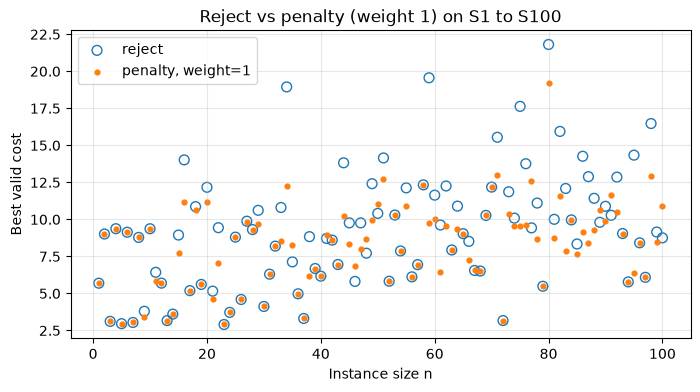

In [36]:
plt.figure(figsize=(8, 4))
plt.scatter(ns, results["reject"], s=50, facecolors="none", edgecolors="tab:blue", label="reject")
plt.scatter(ns, results["weight=1"], s=12, color="tab:orange", label="penalty, weight=1")
plt.xlabel("Instance size n")
plt.ylabel("Best valid cost")
plt.title("Reject vs penalty (weight 1) on S1 to S100")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


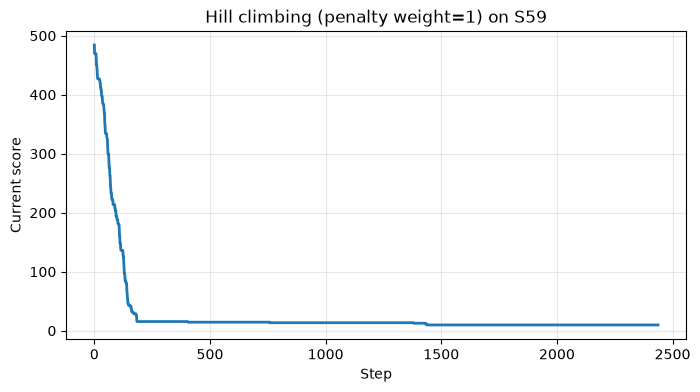

Best solution: frozenset({58}), Best score: 9.777261503573937


In [39]:
inst = single_instance(59)

best, best_score, hist = hill_climb_penalty(inst, Random(0), weight=1)

plt.figure(figsize=(8, 4))                    # new, empty figure: 8 wide, 4 tall (in inches)
plt.plot(hist, linewidth=2)                   # draw the history as a line
plt.xlabel("Step")                            # label the x axis
plt.ylabel("Current score")                    # label the y axis
plt.title("Hill climbing (penalty weight=1) on S59")    # title above the plot
plt.grid(alpha=0.3)                           # faint grid lines (alpha = transparency)
plt.show()                                    # display it
print(f"Best solution: {best}, Best score: {best_score}")
